<a href="https://colab.research.google.com/github/abhiram17082004/Machine-Learning-learningpath/blob/main/notebooks/01_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# ==========================================
# 1. IMPORTING REQUIRED LIBRARIES
# ==========================================

# Pandas:
# Used for loading, reading, manipulating and analysing datasets.
# It provides a DataFrame structure to store tabular data.

import pandas as pd


# NumPy:
# Used for numerical computations.
# Provides support for arrays, mathematical operations and statistics.

import numpy as np


# Matplotlib:
# Used for creating visualizations such as line charts,
# bar charts, histograms and scatter plots.

import matplotlib.pyplot as plt


# Seaborn:
# Built on top of Matplotlib.
# Provides attractive statistical visualizations.
# Useful for understanding relationships between variables.

import seaborn as sns


# Display a confirmation message
print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# ==========================================
# 2. UPLOADING DATASET
# ==========================================

# Import the files module from Google Colab.
# It allows us to upload files directly from our computer.

from google.colab import files

# Open the file upload dialog.
# Select your product_sales.csv file.

uploaded = files.upload()

Saving linear_regression_sample.csv to linear_regression_sample.csv


In [8]:
# ==========================================
# 3. READING DATASET
# ==========================================

# pd.read_csv() reads the CSV file.
# It converts the CSV data into a Pandas DataFrame.
#
# A DataFrame is a two-dimensional tabular structure
# consisting of rows and columns.

df = pd.read_csv("linear_regression_sample.csv")

In [9]:
# ==========================================
# 4. DISPLAY FIRST FIVE ROWS
# ==========================================

# head() displays the first five rows by default.
# This helps us understand the structure and values of our dataset.

df.head()

,product_category,price,discount_pct,month,units_sold_last_4w,units_sold_next_month
0,A,850,0,Jan,15,8
1,B,525,5,Jun,29,26
2,C,875,20,Nov,23,26
3,A,675,0,May,15,21
4,B,500,5,Oct,76,36


In [10]:
# ==========================================
# 5. DISPLAY LAST FIVE ROWS
# ==========================================

# tail() displays the last five rows by default.
# Useful for checking the ending records of the dataset.

df.tail()

,product_category,price,discount_pct,month,units_sold_last_4w,units_sold_next_month
115,B,350,5,Feb,106,58
116,C,975,15,Jul,97,26
117,A,550,5,Jan,101,51
118,B,650,0,Jun,72,35
119,C,500,15,Nov,56,41


In [11]:
# ==========================================
# 6. DATASET DIMENSIONS
# ==========================================

# shape returns a tuple containing:
# (number_of_rows, number_of_columns)

print("Dataset Shape:", df.shape)


# Extract the number of rows and columns separately.

rows = df.shape[0]
columns = df.shape[1]

print("Total Rows:", rows)
print("Total Columns:", columns)

Dataset Shape: (120, 6)
Total Rows: 120
Total Columns: 6


In [12]:
# ==========================================
# 7. DATASET INFORMATION
# ==========================================

# info() provides:
# 1. Column names
# 2. Number of non-null records
# 3. Data types
# 4. Memory usage

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   product_category       120 non-null    object
 1   price                  120 non-null    int64 
 2   discount_pct           120 non-null    int64 
 3   month                  120 non-null    object
 4   units_sold_last_4w     120 non-null    int64 
 5   units_sold_next_month  120 non-null    int64 
dtypes: int64(4), object(2)
memory usage: 5.8+ KB


In [13]:
# ==========================================
# 8. STATISTICAL SUMMARY
# ==========================================

# describe() calculates statistical information
# for numerical columns.

df.describe()

,price,discount_pct,units_sold_last_4w,units_sold_next_month
count,120.000000,120.000000,120.00000,120.000000
mean,652.291667,8.083333,67.95000,38.616667
std,206.562396,6.773134,28.56361,17.687855
min,350.000000,0.000000,13.00000,4.000000
25%,450.000000,0.000000,43.75000,26.000000
50%,650.000000,5.000000,67.50000,38.000000
75%,825.000000,15.000000,93.50000,51.000000
max,1000.000000,20.000000,110.00000,77.000000


In [14]:
# Include both numerical and categorical columns
# in the statistical summary.

df.describe(include="all")

,product_category,price,discount_pct,month,units_sold_last_4w,units_sold_next_month
count,120,120.000000,120.000000,120,120.00000,120.000000
unique,3,NaN,NaN,9,NaN,NaN
top,A,NaN,NaN,Jan,NaN,NaN
freq,40,NaN,NaN,14,NaN,NaN
mean,NaN,652.291667,8.083333,NaN,67.95000,38.616667
std,NaN,206.562396,6.773134,NaN,28.56361,17.687855
min,NaN,350.000000,0.000000,NaN,13.00000,4.000000
25%,NaN,450.000000,0.000000,NaN,43.75000,26.000000
50%,NaN,650.000000,5.000000,NaN,67.50000,38.000000
75%,NaN,825.000000,15.000000,NaN,93.50000,51.000000


In [15]:
# ==========================================
# 9. CHECK MISSING VALUES
# ==========================================

# isnull() checks whether each value is missing.
# It returns True for missing values and False otherwise.

print(df.isnull())


# sum() counts the number of missing values
# in each column.

print("\nMissing values in each column:")
print(df.isnull().sum())

     product_category  price  discount_pct  month  units_sold_last_4w  \
0               False  False         False  False               False   
1               False  False         False  False               False   
2               False  False         False  False               False   
3               False  False         False  False               False   
4               False  False         False  False               False   
..                ...    ...           ...    ...                 ...   
115             False  False         False  False               False   
116             False  False         False  False               False   
117             False  False         False  False               False   
118             False  False         False  False               False   
119             False  False         False  False               False   

     units_sold_next_month  
0                    False  
1                    False  
2                    False  
3      

In [16]:
# ==========================================
# 10. CHECK DUPLICATE RECORDS
# ==========================================

# duplicated() identifies duplicate rows.
# It returns True if a row has already appeared.

print("Duplicate records:")
print(df.duplicated().sum())

Duplicate records:
0


In [17]:
# ==========================================
# 11. CHECK COLUMN DATA TYPES
# ==========================================

# dtypes displays the datatype of every column.

print(df.dtypes)

product_category         object
price                     int64
discount_pct              int64
month                    object
units_sold_last_4w        int64
units_sold_next_month     int64
dtype: object


In [18]:
# ==========================================
# 12. FIND UNIQUE VALUES
# ==========================================

# unique() returns distinct values in a column.

print("Product Categories:")
print(df["product_category"].unique())


print("\nMonths:")
print(df["month"].unique())

Product Categories:
['A' 'B' 'C']

Months:
['Jan' 'Jun' 'Nov' 'May' 'Oct' 'Mar' 'Sep' 'Feb' 'Jul']


In [19]:
# ==========================================
# 13. VALUE COUNTS
# ==========================================

# value_counts() counts how many times
# each unique value appears.

print("Product Category Distribution:")

print(df["product_category"].value_counts())


print("\nMonth Distribution:")

print(df["month"].value_counts())

Product Category Distribution:
product_category
A    40
B    40
C    40
Name: count, dtype: int64

Month Distribution:
month
Jan    14
Jun    14
Nov    14
May    13
Oct    13
Mar    13
Sep    13
Feb    13
Jul    13
Name: count, dtype: int64


In [20]:
# ==========================================
# 14. CALCULATE AVERAGES
# ==========================================

# mean() calculates the arithmetic average.

average_price = df["price"].mean()

average_discount = df["discount_pct"].mean()

average_previous_sales = df["units_sold_last_4w"].mean()

average_next_month_sales = df["units_sold_next_month"].mean()


print("Average Price:", average_price)

print("Average Discount:", average_discount)

print("Average Previous Sales:", average_previous_sales)

print("Average Next Month Sales:", average_next_month_sales)

Average Price: 652.2916666666666
Average Discount: 8.083333333333334
Average Previous Sales: 67.95
Average Next Month Sales: 38.61666666666667


In [21]:
# ==========================================
# 15. MAXIMUM AND MINIMUM SALES
# ==========================================

# max() returns the highest value.
# min() returns the lowest value.

print(
    "Maximum Next Month Sales:",
    df["units_sold_next_month"].max()
)

print(
    "Minimum Next Month Sales:",
    df["units_sold_next_month"].min()
)

Maximum Next Month Sales: 77
Minimum Next Month Sales: 4


In [22]:
# ==========================================
# 16. GROUP BY PRODUCT CATEGORY
# ==========================================

# groupby() groups records based on a column.
#
# Here, we group products by product_category.
# Then calculate average next-month sales for each category.

category_sales = df.groupby(
    "product_category"
)["units_sold_next_month"].mean()


print(category_sales)

product_category
A    50.800
B    35.275
C    29.775
Name: units_sold_next_month, dtype: float64


In [23]:
# ==========================================
# 17. PRICE AND SALES ANALYSIS
# ==========================================

# Group products by price and calculate
# their average next-month sales.

price_sales = df.groupby(
    "price"
)["units_sold_next_month"].mean()


print(price_sales)

price
350     56.333333
375     53.400000
400     44.142857
425     55.750000
450     47.200000
475     50.000000
500     45.333333
525     31.666667
550     52.333333
575      9.000000
625     48.666667
650     39.500000
675     36.500000
700     37.333333
750     23.600000
775     33.625000
800     35.000000
825     31.600000
850     29.500000
875     28.333333
900     30.666667
925     44.333333
950     20.750000
975     22.666667
1000    17.333333
Name: units_sold_next_month, dtype: float64


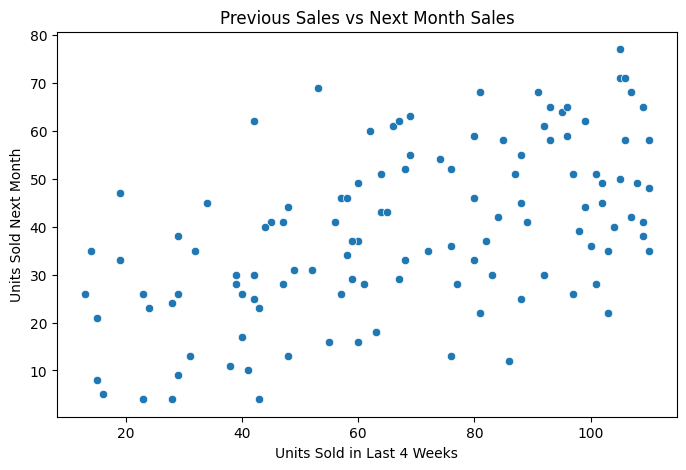

In [24]:
# ==========================================
# 18. SCATTER PLOT
# ==========================================

# figsize defines the width and height of the graph.

plt.figure(figsize=(8, 5))


# scatterplot() creates a graph showing the relationship
# between two numerical variables.

sns.scatterplot(
    data=df,
    x="units_sold_last_4w",
    y="units_sold_next_month"
)


# Add graph title and axis labels.

plt.title("Previous Sales vs Next Month Sales")

plt.xlabel("Units Sold in Last 4 Weeks")

plt.ylabel("Units Sold Next Month")


# Display the graph.

plt.show()

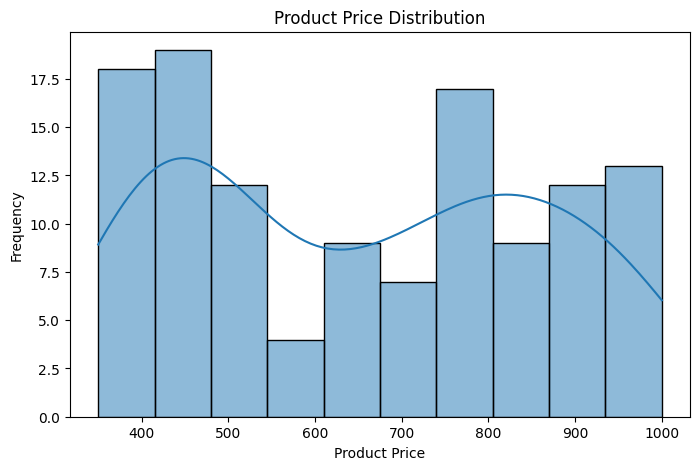

In [25]:
# ==========================================
# 19. HISTOGRAM
# ==========================================

# A histogram shows the distribution of numerical values.
# It helps us understand how frequently different price ranges occur.

plt.figure(figsize=(8, 5))


sns.histplot(
    data=df,
    x="price",
    bins=10,
    kde=True
)


plt.title("Product Price Distribution")

plt.xlabel("Product Price")

plt.ylabel("Frequency")


plt.show()

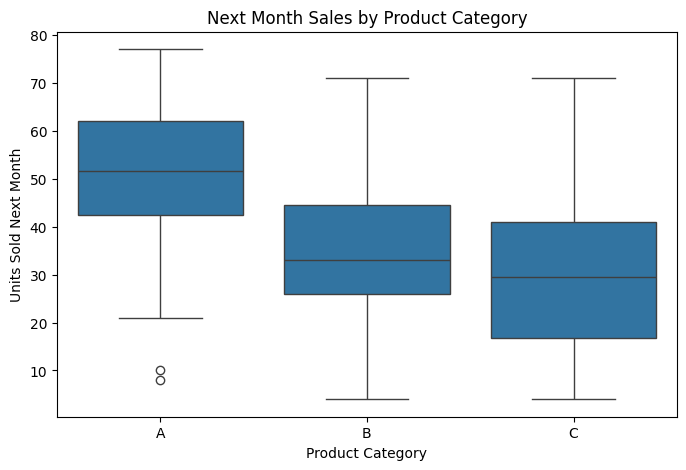

In [26]:
# ==========================================
# 20. BOX PLOT
# ==========================================

# A box plot displays the distribution of values.
# It helps identify median, quartiles and potential outliers.

plt.figure(figsize=(8, 5))


sns.boxplot(
    data=df,
    x="product_category",
    y="units_sold_next_month"
)


plt.title("Next Month Sales by Product Category")

plt.xlabel("Product Category")

plt.ylabel("Units Sold Next Month")


plt.show()

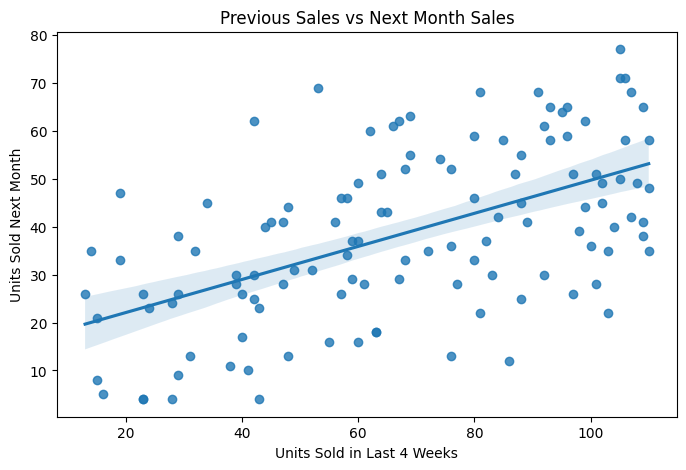

In [27]:
plt.figure(figsize=(8, 5))

# Display dots and add a best-fit regression line
sns.regplot(
    data=df,
    x="units_sold_last_4w",
    y="units_sold_next_month"
)

plt.title("Previous Sales vs Next Month Sales")
plt.xlabel("Units Sold in Last 4 Weeks")
plt.ylabel("Units Sold Next Month")

plt.show()

In [30]:
# X contains the input features
X = df.drop("units_sold_next_month", axis=1)
#axis=0 → Rows
#axis=1 → Columns
#So, df.drop("units_sold_next_month", axis=1) removes the target column from the dataset to create X.

# y contains the target variable
y = df["units_sold_next_month"]

# Display the features
print("Features (X):")
display(X.head())

# Display the target
print("Target (y):")
display(y.head())

Features (X):


,product_category,price,discount_pct,month,units_sold_last_4w
0,A,850,0,Jan,15
1,B,525,5,Jun,29
2,C,875,20,Nov,23
3,A,675,0,May,15
4,B,500,5,Oct,76


Target (y):


,units_sold_next_month
0,8
1,26
2,26
3,21
4,36


In [29]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (120, 5)
y shape: (120,)


In [31]:
# --------------------------------------------------
# ONE-HOT ENCODING
# --------------------------------------------------

# Machine learning algorithms need numerical inputs.
# Our product_category and month columns contain text.
# So, we convert these categorical columns into numbers.

# pd.get_dummies() performs One-Hot Encoding.
# X is our feature dataset.
# columns specifies which columns should be encoded.
# dtype=int ensures that the new columns contain 0 and 1.
X_encoded = pd.get_dummies(
    X,
    columns=["product_category", "month"],
    dtype=int
)

# Display the first 5 rows of the encoded dataset.
# This helps us verify that encoding was performed correctly.
display(X_encoded.head())


# --------------------------------------------------
# CHECK THE DATASET DIMENSIONS
# --------------------------------------------------

# X.shape gives the number of rows and columns
# before encoding.
print("Original X shape:", X.shape)

# X_encoded.shape gives the number of rows and columns
# after encoding.
# Rows should remain the same, but columns will increase.
print("Encoded X shape:", X_encoded.shape)

,price,discount_pct,units_sold_last_4w,product_category_A,product_category_B,product_category_C,month_Feb,month_Jan,month_Jul,month_Jun,month_Mar,month_May,month_Nov,month_Oct,month_Sep
0,850,0,15,1,0,0,0,1,0,0,0,0,0,0,0
1,525,5,29,0,1,0,0,0,0,1,0,0,0,0,0
2,875,20,23,0,0,1,0,0,0,0,0,0,1,0,0
3,675,0,15,1,0,0,0,0,0,0,0,1,0,0,0
4,500,5,76,0,1,0,0,0,0,0,0,0,0,1,0


Original X shape: (120, 5)
Encoded X shape: (120, 15)


In [32]:
# Import train_test_split to divide our dataset into training and testing sets
from sklearn.model_selection import train_test_split

# Split the features (X_encoded) and target (y)
# test_size=0.2 means 20% testing data and 80% training data
# random_state=42 ensures we get the same split every time we run the code
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

# Check how many records are allocated to each set
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (96, 15)
Testing features: (24, 15)
Training target: (96,)
Testing target: (24,)


In [33]:
# Import LinearRegression, which provides the Linear Regression algorithm
from sklearn.linear_model import LinearRegression

# Create an instance of the Linear Regression model
model = LinearRegression()

# Train the model using the training features and their actual target values
# fit() learns the coefficients and intercept from the training data
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [34]:
# Use the trained model to predict next month's sales
# X_test contains 24 records that the model hasn't seen during training
y_pred = model.predict(X_test)

# Display the predicted sales values
print("Predicted Sales:")
print(y_pred)

Predicted Sales:
[18.81604339 21.69791077 43.43914699 25.54746641 41.66614388 54.17235316
  6.95073557 42.14916648 40.39672302 41.56768092 65.04439936 53.36093295
 42.32046056 48.97685649 28.11570145 56.15400377 35.03263146 13.72997009
 33.03506288 51.66826563 38.42002829 64.07909444 29.90637189 22.98365985]


In [35]:
# Create a DataFrame to compare actual and predicted sales
comparison = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

# Calculate the difference between actual and predicted sales
comparison["Difference"] = (
    comparison["Actual Sales"] - comparison["Predicted Sales"]
)

# Display the comparison
display(comparison)

,Actual Sales,Predicted Sales,Difference
0,22,18.816043,3.183957
1,30,21.697911,8.302089
2,36,43.439147,-7.439147
3,23,25.547466,-2.547466
4,42,41.666144,0.333856
5,59,54.172353,4.827647
6,4,6.950736,-2.950736
7,37,42.149166,-5.149166
8,40,40.396723,-0.396723
9,36,41.567681,-5.567681


In [36]:
# Import evaluation metrics from Scikit-learn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# MAE: Average absolute difference between actual and predicted sales
mae = mean_absolute_error(y_test, y_pred)

# MSE: Average of squared prediction errors
mse = mean_squared_error(y_test, y_pred)

# RMSE: Square root of MSE, expressed in units sold
rmse = np.sqrt(mse)

# R2: Measures how well the model explains variation in actual sales
r2 = r2_score(y_test, y_pred)

# Display all evaluation results
print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
MAE: 4.368269842972448
MSE: 26.280179614709482
RMSE: 5.126419765753628
R2 Score: 0.8936712690141282


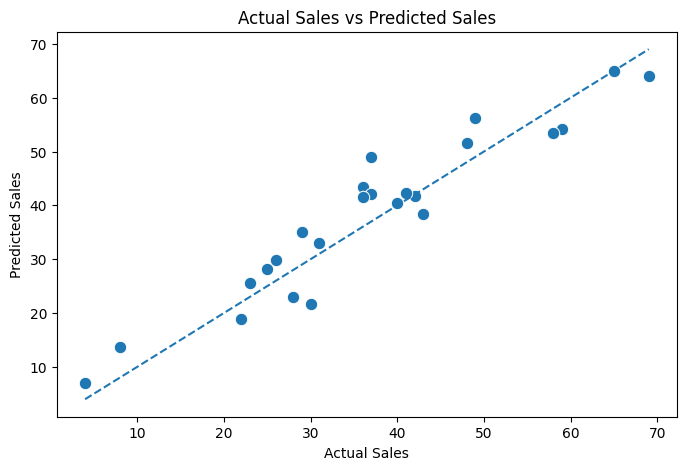

In [37]:
# Create a scatter plot comparing actual and predicted sales
plt.figure(figsize=(8, 5))

# Each dot represents one testing record
sns.scatterplot(x=y_test, y=y_pred, s=80)

# Draw a diagonal reference line representing perfect predictions
# Points closer to this line have smaller prediction errors
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual Sales vs Predicted Sales")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.show()